In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [3]:
observables1 = ['pt','b','w','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','ws','y1s','y2s','phi1s','phi2s','nefs']

In [4]:
df_allreco = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all050124_rc_notrueptcons.root', "MatchedTree"),\
              'pts>15 and bs!=-9 and w<1')

In [6]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    phi1small = min(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi1large = max(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi2small = min(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    phi2large = max(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1']-df_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2']-df_allreco.iloc[i]['y2s'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

In [5]:
df_allreco = applyCut(pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/all050124_rc_notrueptcons.csv', low_memory=False),\
                      'pts>15 and bs!=-9 and w<1')

Process PYTHIA6+GEANT

In [6]:
df_match = applyCut(df_allreco, 'pt!=-9 and b!=-9 and distance1<0.03 and distance2<0.03')
df_allfake = applyCut(df_allreco, 'pt==-9 or b==-9 or distance1>0.03 or distance2>0.03')

In [7]:
print(df_match.shape[0], df_allfake.shape[0])

2668660 1426499


In [8]:
print(np.unique(df_match['bs']))

[-1  1]


In [9]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)],\
                       df_allreco[(df_allreco.pts>40) & (df_allreco.pts<60)]]

df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)] ]

df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)],\
                       df_allfake[(df_allfake.pts>40) & (df_allfake.pts<60)]  ]

In [10]:
rc_allreco_bs_vs_pts_array = []
rc_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[0])
    rc_err_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[1])

In [11]:
plt.rcParams['font.size'] = 12

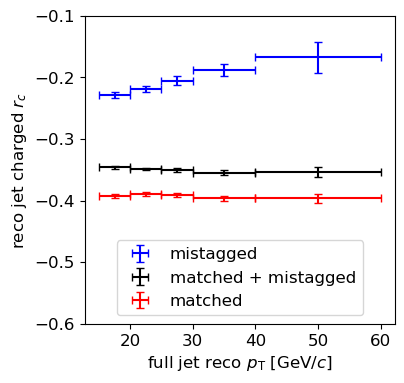

In [12]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allfake_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allfake_bs_vs_pts_array, capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allreco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco jet charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')

In [13]:
rc_allfake_bs_vs_pts_array

[-0.2286877661718943,
 -0.21885907508965927,
 -0.20526118655717468,
 -0.18823054096490408,
 -0.1672850348950648]

In [14]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [15]:
b_fake_array = []
for i in range(0,5):
    df_fake_pts = df_allfake_pts_array[i]
    y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_pts['ws'], density=True)
    b_fake_array.append(y_fake_rec/sum(y_fake_rec))

In [16]:
b_fake_array

[array([0.61434388, 0.38565612]),
 array([0.60942954, 0.39057046]),
 array([0.60263059, 0.39736941]),
 array([0.59411527, 0.40588473]),
 array([0.58364252, 0.41635748])]

In [17]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)]  ]

In [18]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

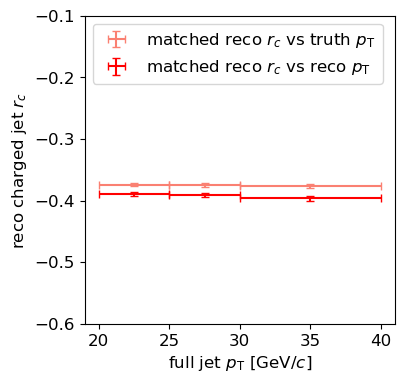

In [19]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='salmon', ls='none', label='matched reco $r_c$ vs truth $p_{\mathrm{T}}$')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched reco $r_c$ vs reco $p_{\mathrm{T}}$')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='upper left')

In [20]:
b_match_array = []
for i in range(0,5):
    df_match_pts = df_match_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_match_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts['ws'], density=True)
    b_match_array.append(y_reco/sum(y_reco))
    print(y_reco/sum(y_reco))

[0.69636375 0.30363625]
[0.6946989 0.3053011]
[0.6955524 0.3044476]
[0.69832931 0.30167069]
[0.69835203 0.30164797]


In [21]:
binedges=[5,10,15,20,25,30,40,60]
match_fake, x = np.histogram(df_allreco['pts'], bins=binedges, weights=df_allreco['ws'])
match, _ = np.histogram(df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_2763728/4101531506.py:4: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


In [22]:
fake_rate_array = np.ones(5)-eff4[2:7]
fake_rate_array

array([0.29936725, 0.24871326, 0.22291703, 0.2064793 , 0.19306711])

Process data

In [23]:
observables1 = ['pt','b']
file = uproot.open('/gpfs/gibbs/project/havener/ys668/rc/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables1, library='np')
df_data = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df_data = applyCut(df_data, 'pts>15 and bs!=-9 and bs!=0')

In [24]:
df_data_pts_array = [ df_data[(df_data.pts>15) & (df_data.pts<20)],\
                       df_data[(df_data.pts>20) & (df_data.pts<25)],\
                       df_data[(df_data.pts>25) & (df_data.pts<30)],\
                       df_data[(df_data.pts>30) & (df_data.pts<40)],\
                       df_data[(df_data.pts>40) & (df_data.pts<60)]  ]

In [25]:
def getRcAndErrAndN(df, ob):
    if (ob == 'bs'):
        nos = df[df.bs==-1].shape[0]
        nss = df[df.bs==+1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n = nss+nos
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err, n

In [26]:
rc_data_bs_vs_pts_array = []
rc_err_data_bs_vs_pts_array = []
for i in range(0, len(df_data_pts_array)):
    rc_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[0])
    rc_err_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[1])

In [27]:
b_data_array = []
for i in range(0,5):
    df_data_pts = df_data_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_data_pts['bs'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
    b_data_array.append(y_reco)

# 1. Mistagged subtraction

In [28]:
def getMatchedCountAndErr(data, fake_rate, fake_dist):
    corrected = data - sum(data) * fake_rate * fake_dist
    err = np.sqrt(corrected)
    return corrected, err

In [16]:
#fake_rate_array = np.array([0.29936704, 0.24871283, 0.22295968, 0.20754411, 0.19886014])
#b_fake_array = np.array([[0.61905176, 0.38094824],[0.61242198, 0.38757802],[0.60408262, 0.39591738],[0.5976935, 0.4023065],[0.59006909, 0.40993091]])

In [29]:
b_fakesubtracted_array = []
b_fakesubtractederr_array = []
rc1_array = []
rc1_err_array = []
for i in range(0,5):
    print(i)
    print(b_data_array[i])
    #print(getRc(data_array[i]))
    b_fakesubtracted, b_fakesubtractederr = getMatchedCountAndErr(b_data_array[i], fake_rate_array[i], b_fake_array[i])
    b_fakesubtracted_array.append(b_fakesubtracted)
    b_fakesubtractederr_array.append(b_fakesubtractederr)
    print(b_fakesubtracted)
    print(b_fakesubtractederr)
    nos = b_fakesubtracted[0]
    nss = b_fakesubtracted[1]
    n = nos + nss
    p = nss / n
    rc1 = (nss-nos) / (nss+nos)
    rc1_array.append(rc1)
    rc1_err_array.append( 2*np.sqrt(p*(1-p)/n) )

0
[337314. 178144.]
[242513.83257428 118632.92573234]
[492.45693474 344.43130771]
1
[72379. 38554.]
[55564.52957368 27777.9625982 ]
[235.72129639 166.66722113]
2
[16450.  8688.]
[13073.04599675  6461.26570578]
[114.33742168  80.38199864]
3
[4758. 2573.]
[3858.68784306 1958.61237237]
[62.11833741 44.25621281]
4
[334. 153.]
[279.12378047 113.8525357 ]
[16.70699795 10.67017037]


In [30]:
print(rc_data_bs_vs_pts_array)

[-0.3087933449476, -0.3049137767841851, -0.30877555891479036, -0.2980493793479744, -0.37166324435318276]


Text(20, -0.2, '$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

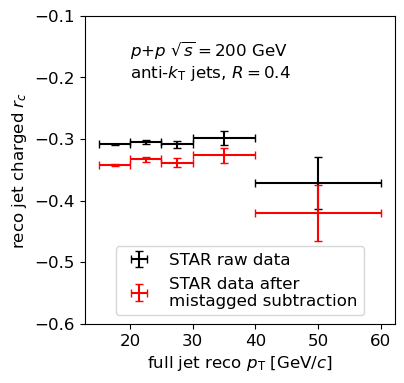

In [31]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_data_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_data_bs_vs_pts_array, capsize=3, color='k', ls='none', label='STAR raw data')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='STAR data after\nmistagged subtraction')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco jet charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.2, '$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

# 2. $p_T$ correction

In [32]:
reweight_array = []
for i in range(0,5):
    reweight = (b_fakesubtracted_array[i]/sum(b_fakesubtracted_array[i]))/(b_match_array[i]/sum(b_match_array[i]))
    reweight_array.append(reweight)

In [33]:
reweight_array

[array([0.96430992, 1.08185214]),
 array([0.95969791, 1.09170559]),
 array([0.96216338, 1.08644297]),
 array([0.94985628, 1.11607634]),
 array([1.01708222, 0.96045256])]

([], [])

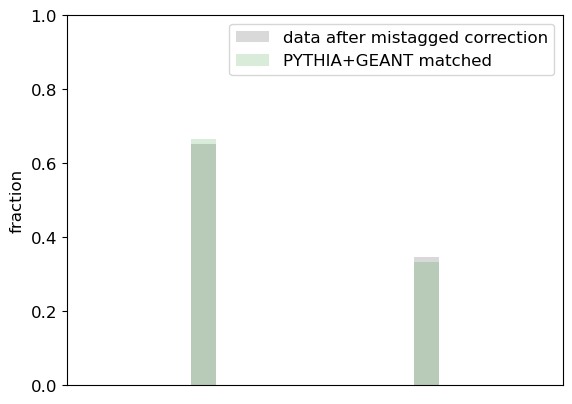

In [34]:
x = np.array([-0.5, 0.5])
plt.hist(x, weights=b_data_array[1]/sum(b_data_array[1]), color='k', alpha=0.15, label='data after mistagged correction')
plt.hist(x, weights=b_fakesubtracted_array[1]/sum(b_fakesubtracted_array[1]), ls='none', color='g', alpha=0.15, label='PYTHIA+GEANT matched')
#plt.errorbar(x+np.array([0.05,-0.05]), b_data_array[1][0]/sum(b_data_array[1]), yerr=y1err_array[0]/sum(b_data_array[1]), capsize=3, color='k', ls='none')
#plt.errorbar(x+np.array([0.05,-0.05]), b_fakesubtracted_array[1][0]/sum(b_fakesubtracted_array[1]), yerr=y1err_pythia_array[0]/sum(b_fakesubtracted_array[1]), capsize=3, color='g', ls='none')
plt.legend(fontsize=12)
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-1,1)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

Reweight PYTHIA6+GEANT

In [35]:
r = []
for i in range(0, df_match.shape[0]):
    if (df_match.iloc[i]['pts'] > 15 and df_match.iloc[i]['pts'] < 20):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[0][0])
        else:
            r.append(reweight_array[0][1])
    elif (df_match.iloc[i]['pts'] > 20 and df_match.iloc[i]['pts'] < 25):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[1][0])
        else:
            r.append(reweight_array[1][1])
    elif (df_match.iloc[i]['pts'] > 25 and df_match.iloc[i]['pts'] < 30):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[2][0])
        else:
            r.append(reweight_array[2][1])
    elif (df_match.iloc[i]['pts'] > 30 and df_match.iloc[i]['pts'] < 40):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[3][0])
        else:
            r.append(reweight_array[3][1])
    elif (df_match.iloc[i]['pts'] > 40 and df_match.iloc[i]['pts'] < 60):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[4][0])
        else:
            r.append(reweight_array[4][1])
    else:
        r.append(1)
        print("anomaly reco pT:", df_match.iloc[i]['pts'])
df_match['r'] = r #

anomaly reco pT: 64.71016459194377
anomaly reco pT: 60.15327606289669
anomaly reco pT: 62.85370544327776
anomaly reco pT: 62.96298659444578
anomaly reco pT: 60.49772873075676
anomaly reco pT: 60.46706627268168
anomaly reco pT: 64.14492779876475
anomaly reco pT: 60.89421353610575
anomaly reco pT: 65.35667922469173
anomaly reco pT: 62.63427678982773
anomaly reco pT: 60.21434194892271
anomaly reco pT: 62.15032283200955
anomaly reco pT: 60.27780299483247
anomaly reco pT: 61.03197986884235
anomaly reco pT: 60.25483540234041
anomaly reco pT: 63.99508646678217
anomaly reco pT: 61.56890722000404
anomaly reco pT: 60.8697641572812
anomaly reco pT: 64.23631221912824
anomaly reco pT: 63.19369788337173
anomaly reco pT: 60.96653998630141
anomaly reco pT: 62.74602930593176
anomaly reco pT: 65.45530859825888
anomaly reco pT: 60.03476303183356
anomaly reco pT: 63.08582949712376
anomaly reco pT: 66.83963074901102
anomaly reco pT: 61.03609940388197
anomaly reco pT: 70.61911542903617
anomaly reco pT: 66.7

anomaly reco pT: 67.37666887910804
anomaly reco pT: 60.35915133914564
anomaly reco pT: 62.49916815883704
anomaly reco pT: 61.066251011791365
anomaly reco pT: 60.35680014528115
anomaly reco pT: 71.33346402750679
anomaly reco pT: 62.32533358538276
anomaly reco pT: 60.92459101037781
anomaly reco pT: 61.37885697371845
anomaly reco pT: 61.45938905164215
anomaly reco pT: 60.16641125403288
anomaly reco pT: 60.09958144920835
anomaly reco pT: 60.511466054485055
anomaly reco pT: 62.350066426895815
anomaly reco pT: 66.11940247976565
anomaly reco pT: 62.15143279465398
anomaly reco pT: 60.697240773348895
anomaly reco pT: 61.79922547972766
anomaly reco pT: 62.11664288908429
anomaly reco pT: 66.38356449440559
anomaly reco pT: 70.6974465514885
anomaly reco pT: 62.49202362716819
anomaly reco pT: 61.065188221162096
anomaly reco pT: 61.23578848561933
anomaly reco pT: 61.52889434809697
anomaly reco pT: 60.31175466428895
anomaly reco pT: 63.22603510311757
anomaly reco pT: 60.18760080128897
anomaly reco pT:

anomaly reco pT: 63.71981930585275
anomaly reco pT: 60.02064456640068
anomaly reco pT: 62.7733686764788
anomaly reco pT: 61.40289010817485
anomaly reco pT: 62.98128569832118
anomaly reco pT: 60.32183562837645
anomaly reco pT: 60.25007160430842
anomaly reco pT: 63.68727178998372
anomaly reco pT: 60.241215702225766
anomaly reco pT: 65.6933023081449
anomaly reco pT: 66.58512231458813
anomaly reco pT: 66.93636831586649
anomaly reco pT: 76.15786384596164
anomaly reco pT: 61.75583943405304
anomaly reco pT: 63.91093010671258
anomaly reco pT: 61.50802846399111
anomaly reco pT: 60.10045488287104
anomaly reco pT: 62.12533305728589
anomaly reco pT: 63.18755753863549
anomaly reco pT: 60.55812705404159
anomaly reco pT: 61.28085631237634
anomaly reco pT: 61.47743287524335
anomaly reco pT: 60.488095763928925
anomaly reco pT: 62.797987637420434
anomaly reco pT: 68.54885901919411
anomaly reco pT: 61.50396984848846
anomaly reco pT: 64.2182142798535
anomaly reco pT: 69.73367420432969
anomaly reco pT: 61.

anomaly reco pT: 61.37535295198051
anomaly reco pT: 61.7756374961377
anomaly reco pT: 60.626293563725305
anomaly reco pT: 63.49412634070907
anomaly reco pT: 70.5174880533174
anomaly reco pT: 62.6662903776326
anomaly reco pT: 62.91756840413069
anomaly reco pT: 71.30840532486586
anomaly reco pT: 60.13583705921202
anomaly reco pT: 61.46443570335763
anomaly reco pT: 67.23187474029625
anomaly reco pT: 64.55607066076693
anomaly reco pT: 61.87475157542629
anomaly reco pT: 60.65666211068506
anomaly reco pT: 60.866841954789045
anomaly reco pT: 62.02669746410887
anomaly reco pT: 61.77017138790346
anomaly reco pT: 65.25033525577705
anomaly reco pT: 61.76350377269977
anomaly reco pT: 67.91261516206957
anomaly reco pT: 64.18896871067179
anomaly reco pT: 61.55566986656164
anomaly reco pT: 61.01320265855932
anomaly reco pT: 66.46683297420948
anomaly reco pT: 60.719874837864914
anomaly reco pT: 63.323007001359706
anomaly reco pT: 61.75751789795584
anomaly reco pT: 65.47874514245692
anomaly reco pT: 63

anomaly reco pT: 60.782299264207786
anomaly reco pT: 63.7562599263892
anomaly reco pT: 61.94242096300837
anomaly reco pT: 61.40510944933873
anomaly reco pT: 60.23472287547592
anomaly reco pT: 74.02151773760512
anomaly reco pT: 60.61806687610212
anomaly reco pT: 65.83267968578859
anomaly reco pT: 61.25843438940521
anomaly reco pT: 66.16120708711156
anomaly reco pT: 65.72664989085668
anomaly reco pT: 65.53033080492808
anomaly reco pT: 60.599082215461976
anomaly reco pT: 67.86706161014762
anomaly reco pT: 61.28741129536817
anomaly reco pT: 60.7486388141404
anomaly reco pT: 64.46143131650787
anomaly reco pT: 62.07810360420189
anomaly reco pT: 60.01648379395155
anomaly reco pT: 64.14932283185601
anomaly reco pT: 61.2409003635572
anomaly reco pT: 60.39707499656056
anomaly reco pT: 61.99196169405341
anomaly reco pT: 60.62075385730599
anomaly reco pT: 61.14995283043609
anomaly reco pT: 66.04902795304733
anomaly reco pT: 60.9882253190428
anomaly reco pT: 66.7477555786966
anomaly reco pT: 61.708

anomaly reco pT: 64.35094256300077
anomaly reco pT: 60.71251028610303
anomaly reco pT: 67.80450198402654
anomaly reco pT: 63.17001812601818
anomaly reco pT: 60.04582936972166
anomaly reco pT: 63.01051187809111
anomaly reco pT: 64.04885365612733
anomaly reco pT: 61.20841531544877
anomaly reco pT: 60.016063930523885
anomaly reco pT: 61.372317158303495
anomaly reco pT: 64.96088080428575
anomaly reco pT: 62.78755970550335
anomaly reco pT: 62.12503417112666
anomaly reco pT: 68.79804384214427
anomaly reco pT: 62.086225423070886
anomaly reco pT: 73.68607240388349
anomaly reco pT: 60.42753267926739
anomaly reco pT: 62.33443166023007
anomaly reco pT: 62.63146783305203
anomaly reco pT: 63.47562451290976
anomaly reco pT: 65.02825410904455
anomaly reco pT: 64.27649357440369
anomaly reco pT: 61.85470868711629
anomaly reco pT: 60.41089807345223
anomaly reco pT: 61.78819791173285
anomaly reco pT: 62.86096768496176
anomaly reco pT: 62.16056113957712
anomaly reco pT: 61.96069542684406
anomaly reco pT: 

... (43 outputs left out)

anomaly reco pT: 60.430477638928
anomaly reco pT: 61.71315311098516
anomaly reco pT: 60.85945754578086
anomaly reco pT: 60.06862333944258
anomaly reco pT: 60.796577602152006
anomaly reco pT: 60.13963615109777
anomaly reco pT: 61.97707944317426
anomaly reco pT: 61.13605801618717
anomaly reco pT: 60.36267681037764
anomaly reco pT: 60.22971271220489
anomaly reco pT: 74.64295382467226
anomaly reco pT: 60.97626442859789
anomaly reco pT: 69.64879673865616
anomaly reco pT: 60.06994195836257
anomaly reco pT: 65.38506653858316
anomaly reco pT: 64.51141181371236
anomaly reco pT: 61.43239476891164
anomaly reco pT: 60.10742816736722
anomaly reco pT: 62.9711334995506
anomaly reco pT: 60.51426174123329
anomaly reco pT: 63.7126828367886
anomaly reco pT: 60.68787718331864
anomaly reco pT: 60.23454726515751
anomaly reco pT: 63.72374753795571
anomaly reco pT: 62.13415474092687
anomaly reco pT: 61.37292760547477
anomaly reco pT: 60.96656571893445
anomaly reco pT: 66.50465798325065
anomaly reco pT: 61.728

anomaly reco pT: 63.23312395465088
anomaly reco pT: 65.96302798676528
anomaly reco pT: 61.09552947718905
anomaly reco pT: 61.17343047347276
anomaly reco pT: 61.98946986641298
anomaly reco pT: 60.4943369207584
anomaly reco pT: 61.11565162412116
anomaly reco pT: 61.084035050284974
anomaly reco pT: 60.04634532820712
anomaly reco pT: 60.76288847004648
anomaly reco pT: 60.46021517963606
anomaly reco pT: 61.54397139009227
anomaly reco pT: 63.87569944102856
anomaly reco pT: 61.14337209371936
anomaly reco pT: 62.17458566387349
anomaly reco pT: 60.72446398534614
anomaly reco pT: 61.35709356965971
anomaly reco pT: 67.00331888979352
anomaly reco pT: 60.02980290742159
anomaly reco pT: 69.71762000778085
anomaly reco pT: 69.19941044301783
anomaly reco pT: 69.23232730047685
anomaly reco pT: 62.844742680124746
anomaly reco pT: 60.199092480136365
anomaly reco pT: 65.74277670677454
anomaly reco pT: 65.45538811978611
anomaly reco pT: 61.29445689114465
anomaly reco pT: 63.29806084595935
anomaly reco pT: 6

anomaly reco pT: 60.529048010718526
anomaly reco pT: 72.08067145056319
anomaly reco pT: 61.43938629362258
anomaly reco pT: 60.77253707911821
anomaly reco pT: 63.15090440375343
anomaly reco pT: 62.47034835868642
anomaly reco pT: 63.896219063439055
anomaly reco pT: 68.42754005349394
anomaly reco pT: 62.1994543567997
anomaly reco pT: 62.072755225195145
anomaly reco pT: 69.50588256654626
anomaly reco pT: 62.185722171069855
anomaly reco pT: 61.0155207423607
anomaly reco pT: 61.66096513584184
anomaly reco pT: 62.72250015561953
anomaly reco pT: 60.84209105174485
anomaly reco pT: 60.65108684954544
anomaly reco pT: 62.14669760902866
anomaly reco pT: 62.27324868221418
anomaly reco pT: 68.87592018830773
anomaly reco pT: 67.50768458549679
anomaly reco pT: 65.62299859039155
anomaly reco pT: 62.67136030764501
anomaly reco pT: 62.32268438080635
anomaly reco pT: 61.04791375123212
anomaly reco pT: 61.25785257404036
anomaly reco pT: 63.387755672272014
anomaly reco pT: 61.07382260631102
anomaly reco pT: 

/tmp/ipykernel_2763728/3883675663.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_match['r'] = r #


In [36]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(np.array(df[df.b==-1]['w'])* np.array(df[df.b==-1]['r']))
        nss = sum(np.array(df[df.b==+1]['w'])* np.array(df[df.b==1]['r']))
    elif (ob == 'b_ch'):
        nos = sum(np.array(df[df.b_ch==-1]['w'])* np.array(df[df.b_ch==-1]['r']))
        nss = sum(np.array(df[df.b_ch==+1]['w'])* np.array(df[df.b_ch==1]['r']))
    elif (ob == 'bs'):
        nos = sum(np.array(df[df.bs==-1]['ws'])* np.array(df[df.bs==-1]['r']))
        nss = sum(np.array(df[df.bs==+1]['ws'])* np.array(df[df.bs==1]['r']))
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    #variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w']) * np.array(df[df.w == w_array[i]]['r']))
        elif (ob == 'b_ch'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))         
        elif (ob == 'bs'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['ws'] * df[df.w == w_array[i]]['r']))
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        #print(variance)
        #variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    #print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

In [37]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)] ]
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)]  ]

In [38]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[1])
rc_match_bs_vs_pts_array_rw = []
rc_err_match_bs_vs_pts_array_rw = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[1])

Check that the reweighted embedding is the same as data

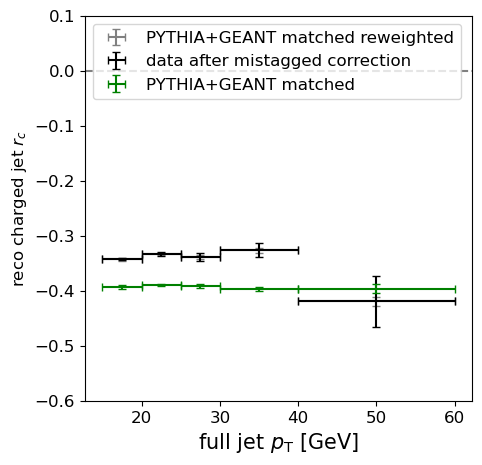

In [45]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array_rw, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array_rw, capsize=3, color='grey', ls='none', label='PYTHIA+GEANT matched reweighted')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='k', ls='none', label='data after mistagged correction')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='g', ls='none', label='PYTHIA+GEANT matched')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [39]:
print(rc_match_bs_vs_pts_array_rw)

[-0.3430209575270323, -0.33340216078268364, -0.338470092604091, -0.3266249635271704, -0.4205628633716676]


Text(20, -0.25, 'STAR data\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

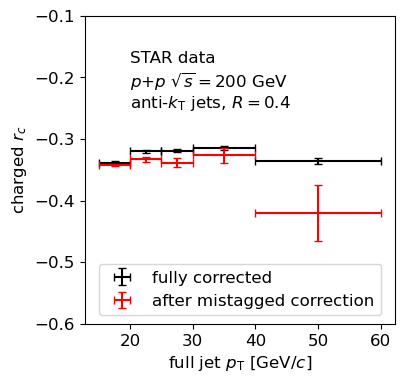

In [40]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='k', ls='none', label='fully corrected')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='after mistagged correction')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.25, 'STAR data\n$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

Plot result

(-0.6, 0.1)

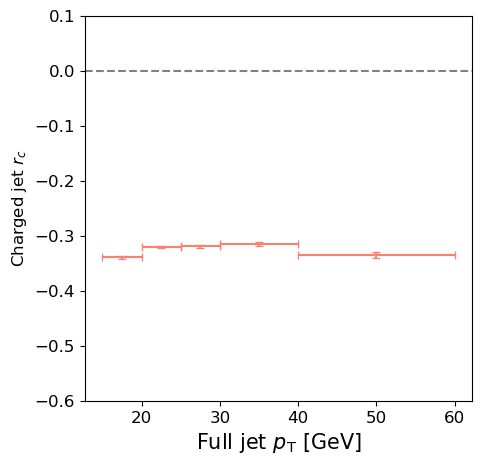

In [41]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='salmon', ls='none', label='sample 1 corrected')
#plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='sample 1 corrected')
plt.xlabel('Full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('Charged jet $r_c$')
plt.ylim(-0.6,0.1)
#plt.legend(loc='upper left', fontsize=15)

In [42]:
rc_match_bs_vs_pt_array

[-0.3389531010521324,
 -0.32020533658349776,
 -0.3191433167976684,
 -0.3147831147110122,
 -0.335404610243962]

In [43]:
rc_err_match_bs_vs_pt_array

[0.0028710733577939646,
 0.0022475642835206775,
 0.0028088170357891667,
 0.003483903663994427,
 0.005196693535367407]